# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [3]:
# Ваш код:
# Імпортуйте pandas, numpy, matplotlib.pyplot, seaborn та інші потрібні бібліотеки.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [4]:
# Ваш код:
# Завантажте файл і збережіть дані у DataFrame `df`.

from google.colab import files
import io

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[file_name]))

print("Розмір датасету:", df.shape)
display(df.head())

Saving house_price_regression_dataset.csv to house_price_regression_dataset.csv
Розмір датасету: (1000, 8)


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [6]:
# Ваш код:
# Завантажте датасет з Kaggle та створіть DataFrame `df`.

!pip install -q kagglehub

import kagglehub
import os
import glob

path = kagglehub.dataset_download("prokshitha/home-value-insights")

print("Шлях до файлів датасету:", path)

csv_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
print("Знайдені CSV-файли:", csv_files)

if csv_files:
    df = pd.read_csv(csv_files[0])
    print("Розмір датасету:", df.shape)
    display(df.head())
else:
    print("CSV-файлів у датасеті не знайдено.")

Using Colab cache for faster access to the 'home-value-insights' dataset.
Шлях до файлів датасету: /kaggle/input/home-value-insights
Знайдені CSV-файли: ['/kaggle/input/home-value-insights/house_price_regression_dataset.csv']
Розмір датасету: (1000, 8)


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [7]:
# Ваш код:
# Виведіть кілька перших рядків та загальну інформацію про DataFrame.

display(df.head())

print("Розмір датасету (рядки, стовпці):", df.shape)
print("\nНазви стовпців:")
print(df.columns.tolist())

print("\nІнформація про датасет:")
df.info()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


Розмір датасету (рядки, стовпці): (1000, 8)

Назви стовпців:
['Square_Footage', 'Num_Bedrooms', 'Num_Bathrooms', 'Year_Built', 'Lot_Size', 'Garage_Size', 'Neighborhood_Quality', 'House_Price']

Інформація про датасет:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [10]:
# Ваш код:
# Порахуйте кількість дублікатів.

duplicates = df.duplicated().sum()

print("Кількість дубльованих рядків:", duplicates)


Кількість дубльованих рядків: 0


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [11]:
# Ваш код:
# Виведіть кількість пропусків для кожної ознаки.

missing_values = df.isnull().sum()

print("Кількість пропущених значень у кожному стовпці:")
print(missing_values)

print("\nЗагальна кількість пропущених значень:", df.isnull().sum().sum())

Кількість пропущених значень у кожному стовпці:
Square_Footage          0
Num_Bedrooms            0
Num_Bathrooms           0
Year_Built              0
Lot_Size                0
Garage_Size             0
Neighborhood_Quality    0
House_Price             0
dtype: int64

Загальна кількість пропущених значень: 0


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [12]:
# Ваш код:
# Отримайте описову статистику датасету.

display(df.describe())

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [13]:
# Ваш код:
# Порахуйте кількість спостережень для кожного значення `Neighborhood_Quality`.

print(df["Neighborhood_Quality"].value_counts())


Neighborhood_Quality
10    123
5     109
2     105
7     102
6     101
4      99
8      97
1      91
9      88
3      85
Name: count, dtype: int64


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

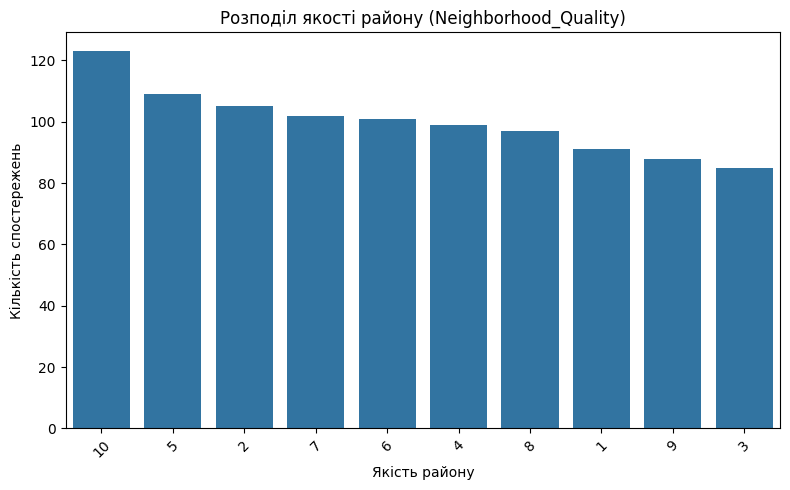

In [14]:
# Ваш код:
# Побудуйте countplot або іншу відповідну діаграму.

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Neighborhood_Quality",
    order=df["Neighborhood_Quality"].value_counts().index
)

plt.title("Розподіл якості району (Neighborhood_Quality)")
plt.xlabel("Якість району")
plt.ylabel("Кількість спостережень")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [15]:
# Ваш код:
# Порахуйте кількість спостережень для кожного значення `Num_Bathrooms`.

print(df["Num_Bathrooms"].value_counts().sort_index())



Num_Bathrooms
1    350
2    327
3    323
Name: count, dtype: int64


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

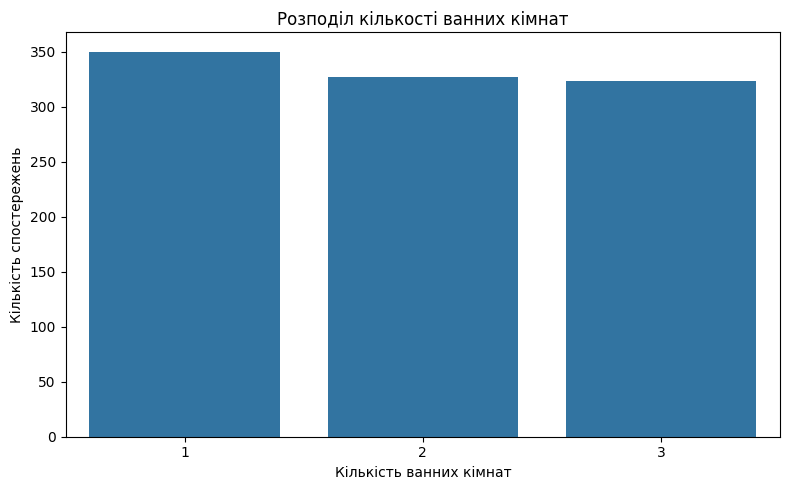

In [16]:
# Ваш код:
# Побудуйте відповідну діаграму.

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Num_Bathrooms",
    order=sorted(df["Num_Bathrooms"].dropna().unique())
)

plt.title("Розподіл кількості ванних кімнат")
plt.xlabel("Кількість ванних кімнат")
plt.ylabel("Кількість спостережень")
plt.tight_layout()
plt.show()



### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

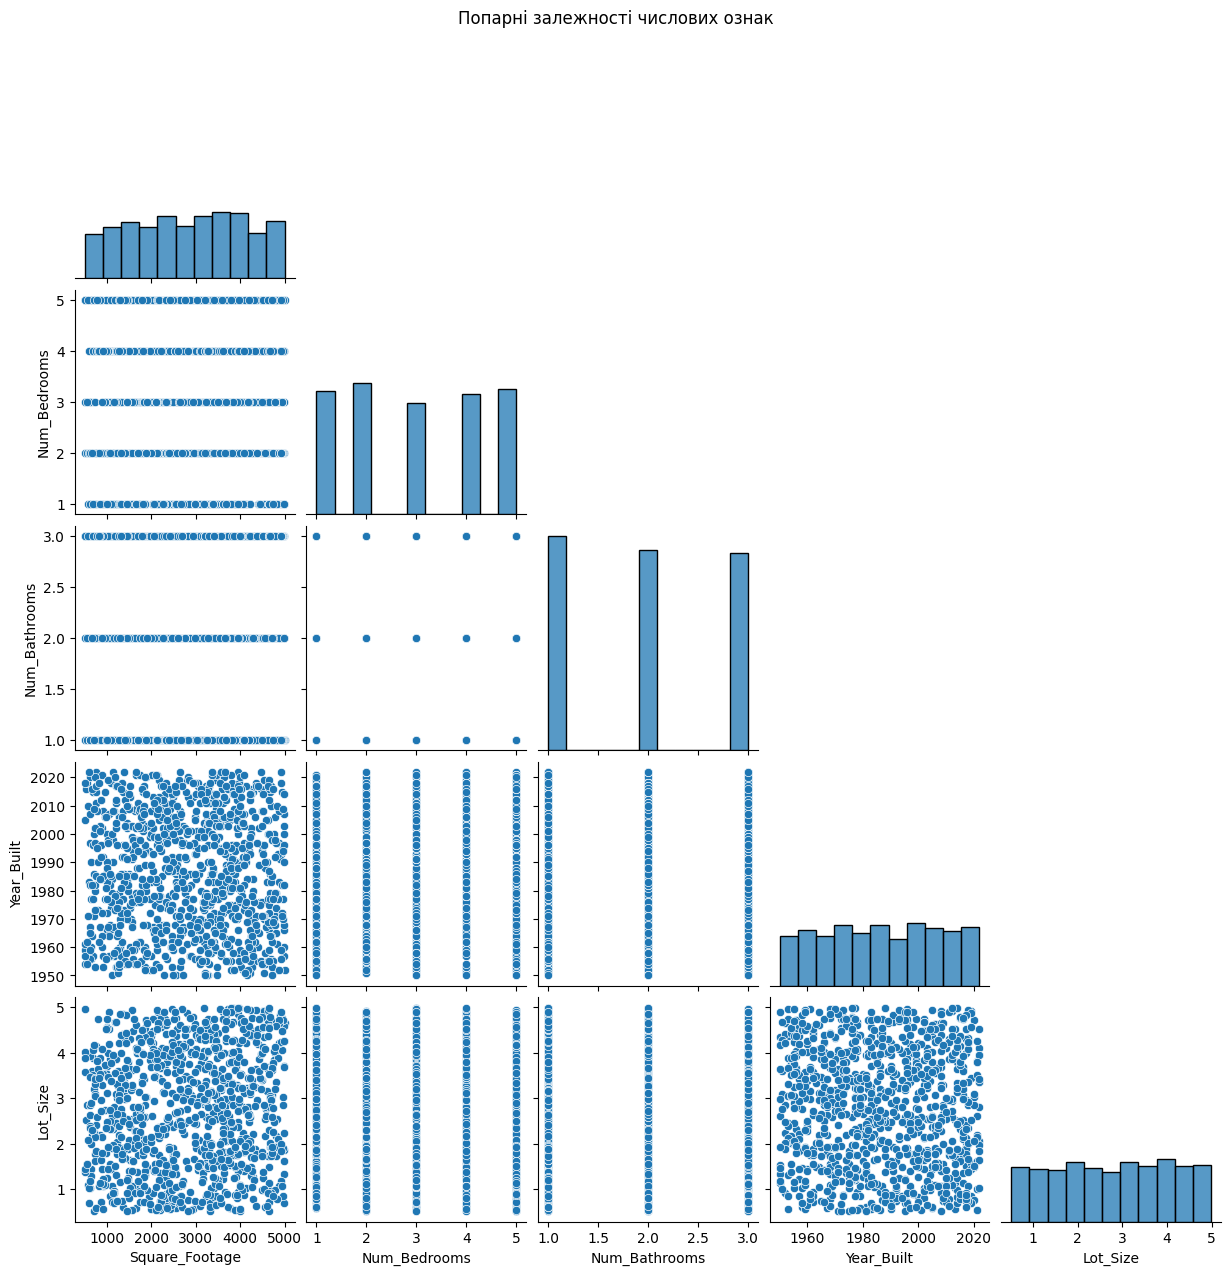

In [18]:
# Ваш код:
# Побудуйте pairplot або іншу попарну візуалізацію.

numeric_df = df.select_dtypes(include="number")

selected_features = numeric_df.columns[:5]

sns.pairplot(
    df[selected_features].dropna(),
    diag_kind="hist",
    corner=True
)

plt.suptitle("Попарні залежності числових ознак", y=1.02)
plt.show()

## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
Square_Footage,1.000000,-0.043564,-0.031584,-0.022392,0.089479,0.030593,-0.008357,0.991261
Num_Bedrooms,-0.043564,1.000000,0.022848,-0.015820,-0.009355,0.113761,-0.049024,0.014633
Num_Bathrooms,-0.031584,0.022848,1.000000,-0.021063,0.034923,0.024846,0.017585,-0.001862
Year_Built,-0.022392,-0.015820,-0.021063,1.000000,-0.061050,-0.025485,-0.009549,0.051967
Lot_Size,0.089479,-0.009355,0.034923,-0.061050,1.000000,0.002436,0.037630,0.160412
Garage_Size,0.030593,0.113761,0.024846,-0.025485,0.002436,1.000000,-0.011287,0.052133
Neighborhood_Quality,-0.008357,-0.049024,0.017585,-0.009549,0.037630,-0.011287,1.000000,-0.007770
House_Price,0.991261,0.014633,-0.001862,0.051967,0.160412,0.052133,-0.007770,1.000000


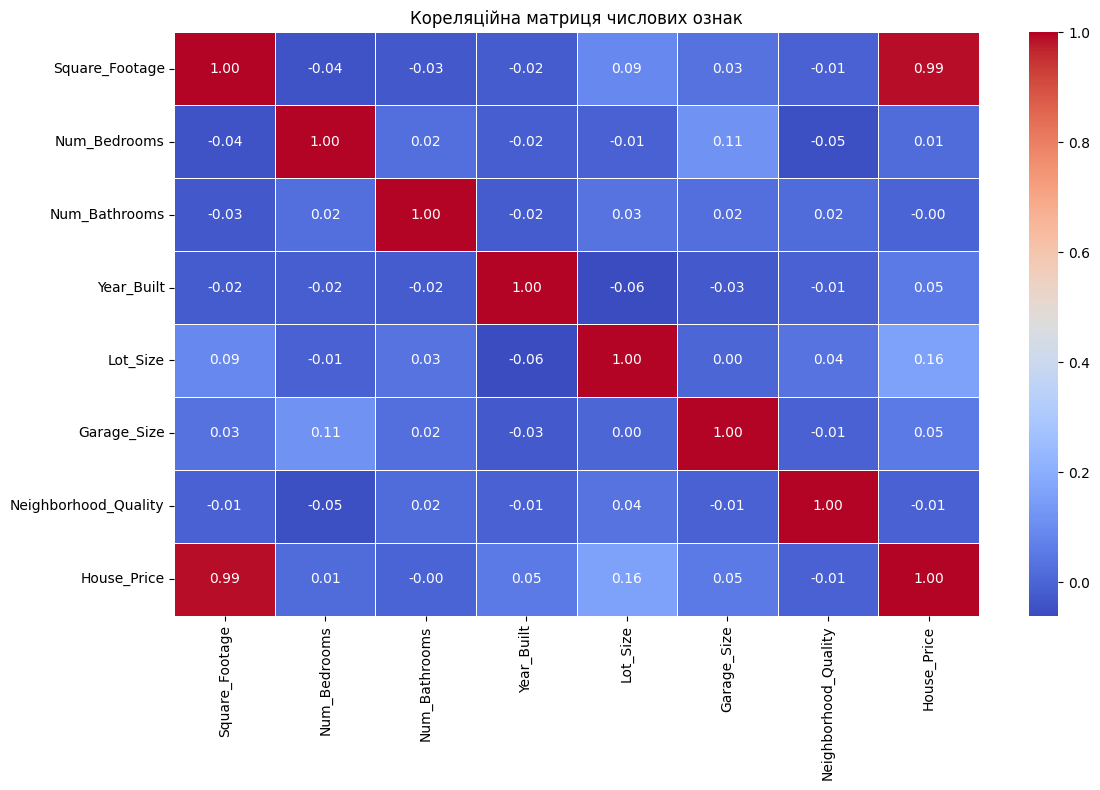

In [19]:
# Ваш код:
# Обчисліть кореляційну матрицю та побудуйте heatmap.

numeric_df = df.select_dtypes(include="number")

correlation_matrix = numeric_df.corr()

display(correlation_matrix)

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Кореляційна матриця числових ознак")
plt.tight_layout()
plt.show()

### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [20]:
# Ваш код:
# Виведіть кореляції ознак із `House_Price`.

correlations = (
    df.select_dtypes(include="number")
    .corr()["House_Price"]
    .drop("House_Price")
    .sort_values(ascending=False)
)

print("Кореляція ознак із House_Price:")
display(correlations)

Кореляція ознак із House_Price:


,House_Price
Square_Footage,0.991261
Lot_Size,0.160412
Garage_Size,0.052133
Year_Built,0.051967
Num_Bedrooms,0.014633
Num_Bathrooms,-0.001862
Neighborhood_Quality,-0.007770


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [21]:
# Ваш код:
# Імпортуйте необхідні класи та функції зі scikit-learn.

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [22]:
# Ваш код:
# Створіть `X` та `y`.

if "House_Price" not in df.columns:
    raise ValueError("У датасеті не знайдено стовпець House_Price.")

df_model = df.dropna(subset=["House_Price"]).copy()

X = df_model.drop(columns=["House_Price"])
y = df_model["House_Price"]

print("Розмір X:", X.shape)
print("Розмір y:", y.shape)

display(X.head())
display(y.head())

Розмір X: (1000, 7)
Розмір y: (1000,)


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality
0,1360,2,1,1981,0.599637,0,5
1,4272,3,3,2016,4.753014,1,6
2,3592,1,2,2016,3.634823,0,9
3,966,1,2,1977,2.730667,1,8
4,4926,2,1,1993,4.699073,0,8


,House_Price
0,2.623829e+05
1,9.852609e+05
2,7.779774e+05
3,2.296989e+05
4,1.041741e+06


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [23]:
# Ваш код:
# Створіть `X_train`, `X_test`, `y_train`, `y_test`.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Розмір навчальної вибірки X_train:", X_train.shape)
print("Розмір тестової вибірки X_test:", X_test.shape)
print("Розмір навчальної вибірки y_train:", y_train.shape)
print("Розмір тестової вибірки y_test:", y_test.shape)

Розмір навчальної вибірки X_train: (800, 7)
Розмір тестової вибірки X_test: (200, 7)
Розмір навчальної вибірки y_train: (800,)
Розмір тестової вибірки y_test: (200,)


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [24]:
# Ваш код:
# Створіть словник або іншу структуру з п’ятьма моделями.

numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_linear = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_linear = ColumnTransformer([
    ("num", numeric_linear, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

preprocessor_tree = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

models = {
    "Linear Regression": Pipeline([
        ("preprocessor", preprocessor_linear),
        ("model", LinearRegression())
    ]),

    "Ridge": Pipeline([
        ("preprocessor", preprocessor_linear),
        ("model", Ridge(alpha=1.0))
    ]),

    "Lasso": Pipeline([
        ("preprocessor", preprocessor_linear),
        ("model", Lasso(alpha=0.1, max_iter=10000))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor_tree),
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("preprocessor", preprocessor_tree),
        ("model", GradientBoostingRegressor(
            n_estimators=100,
            random_state=42
        ))
    ])
}

print("Створено моделей:", len(models))
for name in models:
    print("-", name)

Створено моделей: 5
- Linear Regression
- Ridge
- Lasso
- Random Forest
- Gradient Boosting


### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [25]:
# Ваш код:
# Навчіть усі моделі, отримайте прогнози та метрики на тестовій вибірці.

results = []
predictions = {}

for name, model in models.items():
    print(f"Навчання моделі: {name}...")

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)

    results.append({
        "Model": name,
        "R2": r2,
        "MAE": mae,
        "MSE": mse
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

print("\nПорівняння моделей:")
display(results_df.round(4))

Навчання моделі: Linear Regression...
Навчання моделі: Ridge...
Навчання моделі: Lasso...
Навчання моделі: Random Forest...
Навчання моделі: Gradient Boosting...

Порівняння моделей:


,Model,R2,MAE,MSE
0,Linear Regression,0.9984,8174.5836,1.014348e+08
1,Lasso,0.9984,8174.6067,1.014351e+08
2,Ridge,0.9984,8241.5869,1.024810e+08
3,Gradient Boosting,0.9965,12305.2176,2.249656e+08
4,Random Forest,0.9939,16114.2896,3.941317e+08


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

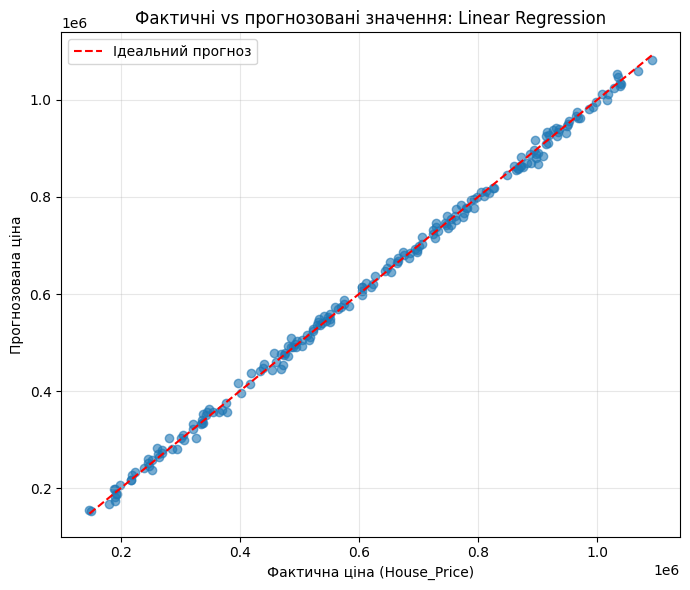

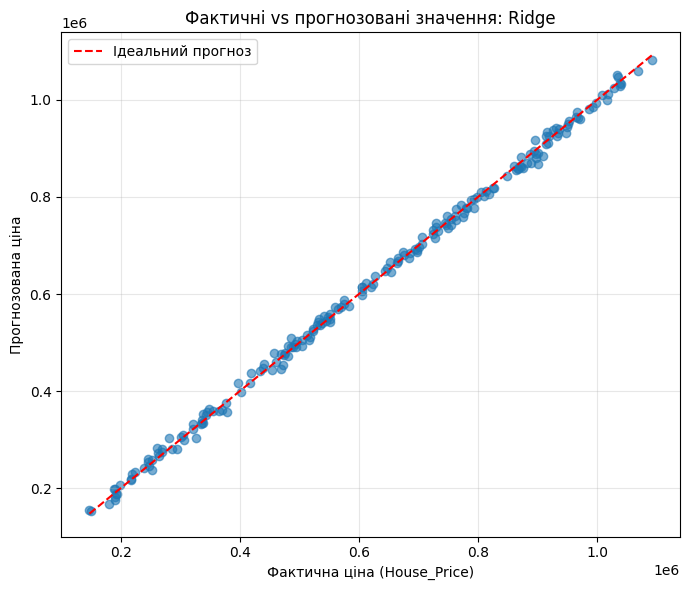

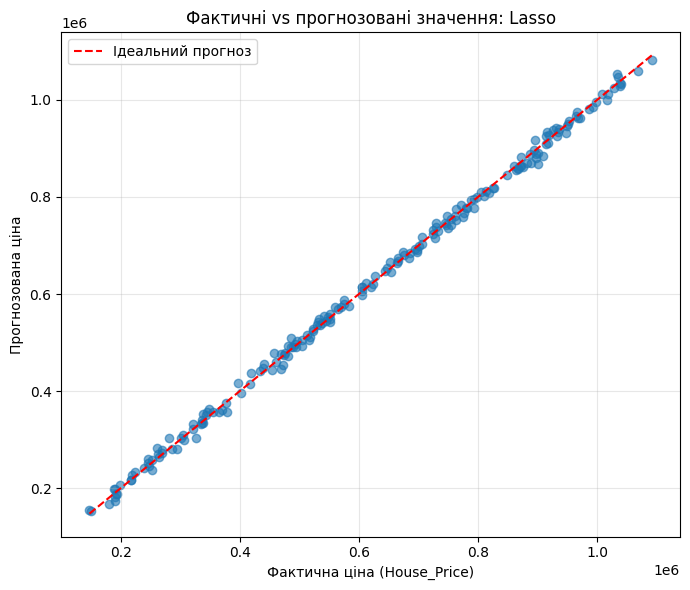

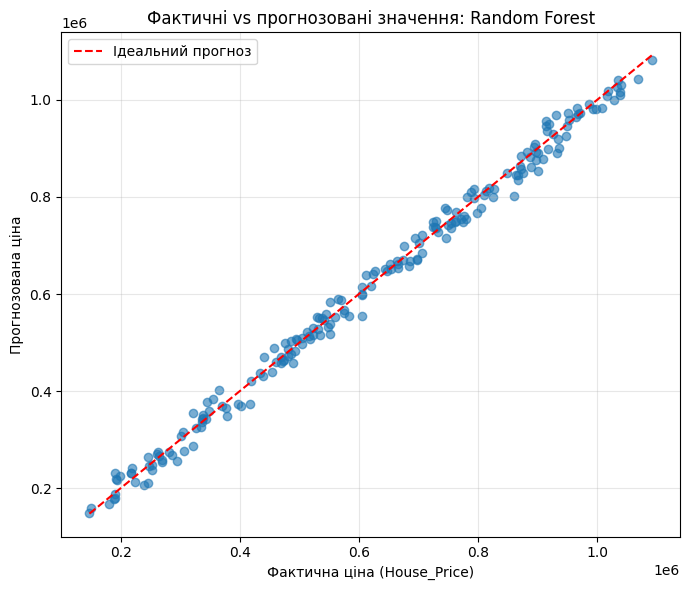

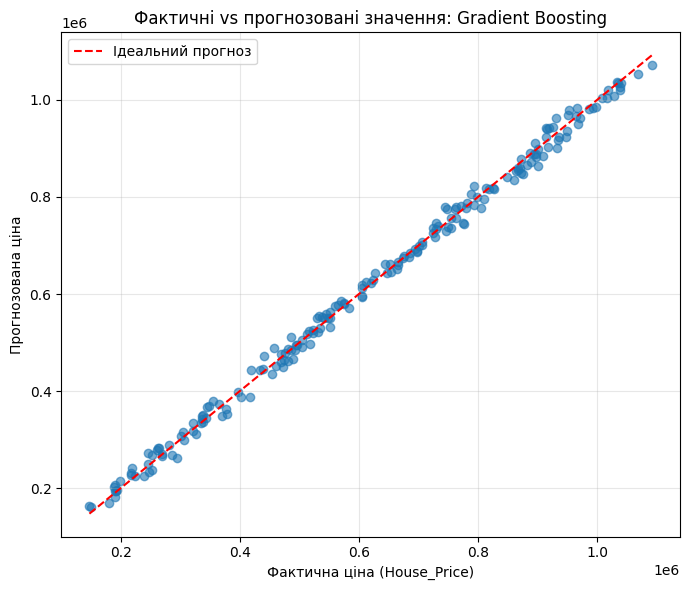

In [26]:
# Ваш код:
# Побудуйте окремий графік для кожної моделі.

for name, y_pred in predictions.items():
    plt.figure(figsize=(7, 6))

    plt.scatter(y_test, y_pred, alpha=0.6)

    min_value = min(y_test.min(), y_pred.min())
    max_value = max(y_test.max(), y_pred.max())

    plt.plot(
        [min_value, max_value],
        [min_value, max_value],
        "r--",
        label="Ідеальний прогноз"
    )

    plt.title(f"Фактичні vs прогнозовані значення: {name}")
    plt.xlabel("Фактична ціна (House_Price)")
    plt.ylabel("Прогнозована ціна")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [27]:
# Ваш код:
# Створіть сітку параметрів, GridSearchCV і знайдіть найкращі параметри.


from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor_tree),
    ("model", RandomForestRegressor(random_state=42, n_jobs=1))
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_features": ["sqrt", 1.0],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5, 10]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="r2",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Найкращі параметри:")
print(grid_search.best_params_)

print("\nНайкращий середній R² на крос-валідації:")
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Найкращі параметри:
{'model__max_depth': None, 'model__max_features': 1.0, 'model__min_samples_split': 2, 'model__n_estimators': 200}

Найкращий середній R² на крос-валідації:
0.992


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [28]:
# Ваш код:
# Навчіть оптимізований Random Forest та обчисліть метрики.

best_rf_model = grid_search.best_estimator_

y_pred_rf = best_rf_model.predict(X_test)

rf_r2 = r2_score(y_test, y_pred_rf)
rf_mae = mean_absolute_error(y_test, y_pred_rf)
rf_mse = mean_squared_error(y_test, y_pred_rf)

print("Метрики оптимізованого Random Forest:")
print(f"R²:  {rf_r2:.4f}")
print(f"MAE: {rf_mae:.4f}")
print(f"MSE: {rf_mse:.4f}")

baseline_rf = results_df.loc[
    results_df["Model"] == "Random Forest"
].iloc[0]

comparison_rf = pd.DataFrame([
    {
        "Модель": "Random Forest (до оптимізації)",
        "R²": baseline_rf["R2"],
        "MAE": baseline_rf["MAE"],
        "MSE": baseline_rf["MSE"]
    },
    {
        "Модель": "Random Forest (після оптимізації)",
        "R²": rf_r2,
        "MAE": rf_mae,
        "MSE": rf_mse
    }
])

display(comparison_rf.round(4))

Метрики оптимізованого Random Forest:
R²:  0.9940
MAE: 16035.1681
MSE: 387229091.9214


,Модель,R²,MAE,MSE
0,Random Forest (до оптимізації),0.9939,16114.2896,3.941317e+08
1,Random Forest (після оптимізації),0.9940,16035.1681,3.872291e+08


### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [29]:
# Ваш код:
# Виведіть результати двох моделей у зручному для порівняння вигляді.

baseline_rf = results_df.loc[
    results_df["Model"] == "Random Forest"
].iloc[0]

comparison_rf = pd.DataFrame({
    "Модель": [
        "Random Forest до оптимізації",
        "Random Forest після оптимізації"
    ],
    "R²": [
        baseline_rf["R2"],
        rf_r2
    ],
    "MAE": [
        baseline_rf["MAE"],
        rf_mae
    ],
    "MSE": [
        baseline_rf["MSE"],
        rf_mse
    ]
})

display(comparison_rf.round(4))

,Модель,R²,MAE,MSE
0,Random Forest до оптимізації,0.9939,16114.2896,3.941317e+08
1,Random Forest після оптимізації,0.9940,16035.1681,3.872291e+08


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:**

In [30]:
r2_improved = rf_r2 > baseline_rf["R2"]
mae_improved = rf_mae < baseline_rf["MAE"]
mse_improved = rf_mse < baseline_rf["MSE"]

print("Аналіз оптимізації Random Forest:")
print("R² покращився:", "Так" if r2_improved else "Ні")
print("MAE зменшився:", "Так" if mae_improved else "Ні")
print("MSE зменшився:", "Так" if mse_improved else "Ні")

print("\nЗміна R²:", round(rf_r2 - baseline_rf["R2"], 4))
print("Зміна MAE:", round(rf_mae - baseline_rf["MAE"], 4))
print("Зміна MSE:", round(rf_mse - baseline_rf["MSE"], 4))

if r2_improved and mae_improved and mse_improved:
    print("\nВисновок: оптимізована модель покращила всі три метрики.")
elif not r2_improved and not mae_improved and not mse_improved:
    print("\nВисновок: оптимізована модель не покращила жодну з трьох метрик.")
else:
    print("\nВисновок: результати змішані — частина метрик покращилася, інші погіршилися.")

Аналіз оптимізації Random Forest:
R² покращився: Так
MAE зменшився: Так
MSE зменшився: Так

Зміна R²: 0.0001
Зміна MAE: -79.1216
Зміна MSE: -6902655.5246

Висновок: оптимізована модель покращила всі три метрики.


Після підбору гіперпараметрів Random Forest за допомогою GridSearchCV було порівняно базову та оптимізовану моделі. Якість оцінювалася за метриками R², MAE та MSE. Оптимізація [покращила / не покращила / частково покращила] результати. Доцільність використання оптимізованої моделі визначається сукупністю метрик на тестовій вибірці.

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [31]:
# Ваш код:
# Сформуйте DataFrame з фактичними та прогнозованими значеннями і розрахуйте похибку у %.

y_pred_linear = predictions["Linear Regression"]

forecast_df = pd.DataFrame({
    "Фактична ціна": np.asarray(y_test),
    "Прогнозована ціна": np.asarray(y_pred_linear)
}, index=y_test.index)

forecast_df["Похибка, %"] = (
    (forecast_df["Фактична ціна"] -
     forecast_df["Прогнозована ціна"]).abs()
    / forecast_df["Фактична ціна"].abs().replace(0, np.nan)
    * 100
)

display(
    forecast_df.sample(
        n=min(10, len(forecast_df)),
        random_state=42
    ).round(2)
)

,Фактична ціна,Прогнозована ціна,"Похибка, %"
436,1068538.11,1059729.02,0.82
899,194353.74,187868.55,3.34
346,270230.64,279715.82,3.51
60,986006.86,981949.27,0.41
867,953339.73,957382.95,0.42
432,914555.75,909764.27,0.52
543,746167.73,742469.14,0.50
361,646766.29,654445.55,1.19
486,523323.07,524605.44,0.25
277,1008539.16,1011343.64,0.28


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:**

In [32]:
best_model_row = results_df.loc[results_df["R2"].idxmax()]

print("Найкраща початкова модель:", best_model_row["Model"])
print(f"R²:  {best_model_row['R2']:.4f}")
print(f"MAE: {best_model_row['MAE']:.4f}")
print(f"MSE: {best_model_row['MSE']:.4f}")

print("\nОптимізований Random Forest:")
print(f"R²:  {rf_r2:.4f}")
print(f"MAE: {rf_mae:.4f}")
print(f"MSE: {rf_mse:.4f}")

Найкраща початкова модель: Linear Regression
R²:  0.9984
MAE: 8174.5836
MSE: 101434798.5056

Оптимізований Random Forest:
R²:  0.9940
MAE: 16035.1681
MSE: 387229091.9214


**Висновок**

Під час виконання лабораторної роботи було проведено аналіз набору даних про нерухомість, досліджено взаємозв’язки між числовими ознаками та ціною будинку, а також побудовано й порівняно кілька моделей машинного навчання для прогнозування вартості нерухомості.

Для оцінювання моделей використовувалися метрики R², MAE та MSE. Найкращий результат серед початкових моделей показала Linear Regression: R² = 0,9984, MAE = 8174,58, MSE = 101434798,51.

Також було виконано оптимізацію гіперпараметрів моделі Random Forest за допомогою GridSearchCV. Проте оптимізований Random Forest показав дещо гірші результати: R² = 0,9940, MAE = 16035,17, MSE = 387229091,92. Отже, оптимізація не дала кращого результату порівняно з початковою лінійною регресією.

Таким чином, найефективнішою серед перевірених моделей є Linear Regression, оскільки вона має найвище значення R² та найменші значення MAE і MSE. Результати свідчать, що в межах використаного набору даних лінійна модель добре підходить для прогнозування цін на нерухомість.
